# DS-04 — Baselines: Opportunity Win Probability

**Mục tiêu:** ≥3 baseline cho Win Probability, đánh giá theo **time split**, leakage check, ROC-AUC/PR-AUC/Top-30%-Precision và calibration.

- 1 dòng = 1 Opportunity có ít nhất 1 Quotation.
- `as_of_date` = ngày Quotation đầu tiên.
- Time split là primary holdout của Win Probability.
- Không dùng feature nhìn thấy thông tin sau `as_of_date`.
- Không tuning chỉ để làm metric đẹp.


## 1. Trạng thái dataset sau rebuild

Dataset hiện tại đã được rebuild sau khi sửa các lỗi seed ở DS-03:

- Tổng Opportunity: **183**
- Có Quotation: **119**
- `out_of_scope_no_quotation`: **64 (35.0%)**
- `closed_lost`: **64**
- `closed_won`: **55**
- Trainable: **119 (65.0%)**
- Won rate trên trainable: **46.2%**
- Train: **84**
- Test: **35**

64 Opportunity chưa từng có Quotation là **out-of-scope**, không coi là right-censored.

### Leakage đã loại khỏi baseline

- `n_quotation_total`: có thể đếm quotation phát sinh sau `as_of_date`.
- `owner_historic_win_rate`: cách gate lịch sử chưa dựa trên ngày biết kết quả thật và có thể tự tính chính Opportunity hiện tại.

### Feature phải loại khỏi model

`opportunity_type` chỉ có một giá trị trong dataset hiện tại, vì mọi Opportunity đều là Gói thầu. Feature này không có variation nên **không đưa vào model**.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import CalibrationDisplay
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

TRAIN_PATH = "win_probability_train.csv"
TEST_PATH = "win_probability_test.csv"

RANDOM_STATE = 42
N_SPLITS = 5
TOP_K_FRAC = 0.30

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

for df in (train, test):
    df["as_of_date"] = pd.to_datetime(df["as_of_date"], errors="coerce")

print(f"Train: {len(train)} dòng")
print(f"Test : {len(test)} dòng")
print("\nTrain label distribution:")
print(train["label"].value_counts().sort_index())
print("\nTest label distribution:")
print(test["label"].value_counts().sort_index())


Train: 84 dòng
Test : 35 dòng

Train label distribution:
label
0    49
1    35
Name: count, dtype: int64

Test label distribution:
label
0    15
1    20
Name: count, dtype: int64


## 2. Time split / leakage check

Win Probability có 1 dòng = 1 Opportunity nên không cần group split.

Primary requirement là:

```text
max(train.as_of_date) <= min(test.as_of_date)
```

Nếu điều kiện này không đúng, notebook phải dừng vì có nguy cơ dùng Opportunity tương lai để đánh giá model.


In [2]:
train_max_date = train["as_of_date"].max()
test_min_date = test["as_of_date"].min()

print(f"max(train as_of_date) = {train_max_date.date()}")
print(f"min(test as_of_date)  = {test_min_date.date()}")

assert train_max_date <= test_min_date, (
    "TIME LEAKAGE: train chứa snapshot muộn hơn test."
)

print("[Time leakage check] OK")


max(train as_of_date) = 2026-05-03
min(test as_of_date)  = 2026-05-08
[Time leakage check] OK


## 3. Feature audit

Feature hợp lệ phải có thể biết tại `as_of_date`.

Không đưa vào model:

- `label`
- `opportunity_id`
- `as_of_date`
- `censor_status`
- `quotation_date`
- `n_quotation_total`
- `owner_historic_win_rate`
- `has_quotation`
- `opportunity_type` vì constant/no variation

Không tự biến missing thành giá trị nghiệp vụ giả như `0` hoặc `"Unknown"`. Missing numeric được xử lý bằng median imputation **bên trong pipeline**, chỉ fit trên training fold.


In [3]:
TARGET = "label"

# WHITELIST — chỉ các feature đã được chốt cho baseline Win Probability.
# Không dùng blacklist để tránh cột mới/identifier tự động lọt vào model.
feature_whitelist = [
    "lead_source",
    "customer_segment",
    "territory",
    "opportunity_amount",
    "days_lead_to_opp",
    "discount_rate_at_first_quotation",
]

missing_train = [c for c in feature_whitelist if c not in train.columns]
missing_test = [c for c in feature_whitelist if c not in test.columns]
if missing_train or missing_test:
    raise KeyError(
        f"Thiếu feature theo whitelist. train={missing_train}, test={missing_test}"
    )

# Loại trừ các cột gây rò rỉ dữ liệu hoặc không phải là biến đặc trưng đã biết.
for forbidden in [
    "n_quotation_total",
    "owner_historic_win_rate",
    "opportunity_type",
    "opportunity_id",
    "as_of_date",
    "censor_status",
]:
    assert forbidden not in feature_whitelist

features = feature_whitelist

X_train = train[features].copy()
X_test = test[features].copy()
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in features if c not in numeric_features]

print("Final model features:", features)
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

audit = pd.DataFrame({
    "feature": features,
    "dtype": [str(train[c].dtype) for c in features],
    "train_missing_pct": [train[c].isna().mean() for c in features],
    "test_missing_pct": [test[c].isna().mean() for c in features],
    "train_observed": [train[c].notna().sum() for c in features],
    "train_nunique": [train[c].nunique(dropna=True) for c in features],
})
display(audit)


Final model features: ['lead_source', 'customer_segment', 'territory', 'opportunity_amount', 'days_lead_to_opp', 'discount_rate_at_first_quotation']
Numeric: ['opportunity_amount', 'days_lead_to_opp', 'discount_rate_at_first_quotation']
Categorical: ['lead_source', 'customer_segment', 'territory']


,feature,dtype,train_missing_pct,test_missing_pct,train_observed,train_nunique
0,lead_source,object,0.000000,0.000000,84,6
1,customer_segment,object,0.000000,0.000000,84,4
2,territory,object,0.000000,0.000000,84,3
3,opportunity_amount,float64,0.000000,0.000000,84,7
4,days_lead_to_opp,float64,0.345238,0.428571,55,17
5,discount_rate_at_first_quotation,float64,0.000000,0.000000,84,6


### Feature audit hiện tại đã xác nhận

| Feature | Train missing | Test missing | Train observed | Nunique |
|---|---:|---:|---:|---:|
| `opportunity_amount` | 0% | 0% | 84 | 7 |
| `days_lead_to_opp` | 34.5% | 42.9% | 55 | 17 |
| `discount_rate_at_first_quotation` | 0% | 0% | 84 | 6 |
| `lead_source` | 0% | 0% | 84 | 6 |
| `customer_segment` | 0% | 0% | 84 | 4 |
| `territory` | 0% | 0% | 84 | 3 |
| `opportunity_type` | 0% | 0% | 84 | 1 |

`opportunity_type` được loại vì constant. Các feature còn lại được giữ vì có variation.


## 4. Ba baseline

Không thực hiện hyperparameter search.

Mục tiêu của DS-04 là thiết lập baseline có thể tái lập và trung thực, không phải tối ưu score.

- **Logistic Regression:** baseline tuyến tính.
- **Random Forest:** baseline tree ensemble.
- **CatBoost:** baseline boosting.

`StratifiedKFold(5)` chỉ dùng trên training set.


In [4]:
# Tiền xử lý dữ liệu cho Logistic Regression /Random Forest

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in features if c not in numeric_features]

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        numeric_features,
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]),
        categorical_features,
    ),
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['opportunity_amount', 'days_lead_to_opp', 'discount_rate_at_first_quotation']
Categorical features: ['lead_source', 'customer_segment', 'territory']


In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "CatBoost": Pipeline([
        ("prep", preprocessor),
        ("model", CatBoostClassifier(
            iterations=300,
            depth=5,
            learning_rate=0.05,
            loss_function="Logloss",
            verbose=False,
            random_seed=RANDOM_STATE,
        )),
    ]),
}

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print(
    f"[CV caveat] {len(train)} Opportunity train, "
    f"lớp thiểu số = {y_train.value_counts().min()} "
    f"→ StratifiedKFold({N_SPLITS})."
)


[CV caveat] 84 Opportunity train, lớp thiểu số = 35 → StratifiedKFold(5).


In [6]:
def top_k_precision(y_true, y_score, frac=0.30):
    k = max(1, int(np.ceil(len(y_true) * frac)))
    order = np.argsort(-np.asarray(y_score))[:k]
    return np.asarray(y_true)[order].mean(), k

results = []
predictions = {}
cv_details = {}

for name, model in models.items():
    fold_auc = []

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
        X_tr = X_train.iloc[tr_idx]
        y_tr = y_train.iloc[tr_idx]
        X_va = X_train.iloc[va_idx]
        y_va = y_train.iloc[va_idx]

        model.fit(X_tr, y_tr)
        p_va = model.predict_proba(X_va)[:, 1]
        fold_auc.append(roc_auc_score(y_va, p_va))

    # Huấn luyện mô hình cơ sở cuối cùng trên toàn bộ dữ liệu huấn luyện 
    # sau đó đánh giá một lần trên tập kiểm tra chưa từng được sử dụng.
    model.fit(X_train, y_train)
    p_test = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, p_test)
    pr_auc = average_precision_score(y_test, p_test)
    top_p, k = top_k_precision(y_test.to_numpy(), p_test, TOP_K_FRAC)

    predictions[name] = p_test
    cv_details[name] = np.asarray(fold_auc)

    results.append({
        "model": name,
        "auc": auc,
        "pr_auc": pr_auc,
        "top_30_precision": top_p,
        "top_k": k,
        "cv_auc_mean": np.mean(fold_auc),
        "cv_auc_std": np.std(fold_auc, ddof=1),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("auc", ascending=False)
    .reset_index(drop=True)
)

display(results_df)

for name, scores in cv_details.items():
    print(
        f"{name}\n"
        f"CV ROC-AUC: {np.round(scores, 3)} | "
        f"mean={scores.mean():.3f} | std={scores.std(ddof=1):.3f}"
    )


,model,auc,pr_auc,top_30_precision,top_k,cv_auc_mean,cv_auc_std
0,Random Forest,0.526667,0.652054,0.545455,11,0.621905,0.138448
1,CatBoost,0.513333,0.652223,0.636364,11,0.603810,0.089999
2,Logistic Regression,0.456667,0.620666,0.454545,11,0.539683,0.140837


Logistic Regression
CV ROC-AUC: [0.7   0.371 0.614 0.6   0.413] | mean=0.540 | std=0.141
Random Forest
CV ROC-AUC: [0.514 0.557 0.671 0.843 0.524] | mean=0.622 | std=0.138
CatBoost
CV ROC-AUC: [0.571 0.6   0.657 0.714 0.476] | mean=0.604 | std=0.090


## 5. Kết quả baseline

Bảng metric bên dưới phải được **sinh trực tiếp từ `results_df` của chính lần chạy notebook**.

Không hard-code các AUC/PR-AUC/Top-30% vào markdown, vì như vậy rất dễ mang số từ một run cũ sang dataset/run mới.

Quy tắc diễn giải:

- model có `cv_auc_mean` cao nhất là CV leader;
- model có `auc` cao nhất là test ROC-AUC leader;
- model có `pr_auc` hoặc `top_30_precision` cao nhất được báo cáo riêng;
- không chọn model chỉ từ một metric;
- test chỉ có 35 Opportunity nên mọi kết luận phải kèm caveat về sample size.


In [7]:
# Bảng báo cáo từ results_df
report_results = results_df[
    [
        "model",
        "cv_auc_mean",
        "cv_auc_std",
        "auc",
        "pr_auc",
        "top_30_precision",
    ]
].copy()

report_results = report_results.rename(columns={
    "model": "Model",
    "cv_auc_mean": "CV ROC-AUC mean",
    "cv_auc_std": "CV ROC-AUC std",
    "auc": "Test ROC-AUC",
    "pr_auc": "Test PR-AUC",
    "top_30_precision": "Top-30% Precision",
})

display(report_results.round(3))

cv_leader = results_df.loc[results_df["cv_auc_mean"].idxmax()]
auc_leader = results_df.loc[results_df["auc"].idxmax()]
pr_leader = results_df.loc[results_df["pr_auc"].idxmax()]
top30_leader = results_df.loc[results_df["top_30_precision"].idxmax()]

print(f"CV ROC-AUC leader      : {cv_leader['model']} ({cv_leader['cv_auc_mean']:.3f})")
print(f"Test ROC-AUC leader    : {auc_leader['model']} ({auc_leader['auc']:.3f})")
print(f"Test PR-AUC leader     : {pr_leader['model']} ({pr_leader['pr_auc']:.3f})")
print(
    f"Top-30% Precision leader: "
    f"{top30_leader['model']} ({top30_leader['top_30_precision']:.3f})"
)


,Model,CV ROC-AUC mean,CV ROC-AUC std,Test ROC-AUC,Test PR-AUC,Top-30% Precision
0,Random Forest,0.622,0.138,0.527,0.652,0.545
1,CatBoost,0.604,0.090,0.513,0.652,0.636
2,Logistic Regression,0.540,0.141,0.457,0.621,0.455


CV ROC-AUC leader      : Random Forest (0.622)
Test ROC-AUC leader    : Random Forest (0.527)
Test PR-AUC leader     : CatBoost (0.652)
Top-30% Precision leader: CatBoost (0.636)


## 6. Calibration

Calibration được chạy trên **test set** để mô tả hành vi của probability output.

**Caveat bắt buộc:** test chỉ có 35 Opportunity nên mỗi bin có rất ít quan sát. Không kết luận model đã calibrated tốt hoặc kém chỉ từ calibration curve này.

Calibration ở đây là một yêu cầu của DS-04 và một kiểm tra thăm dò; muốn dùng probability như xác suất tuyệt đối trong nghiệp vụ cần thêm dữ liệu/validation.


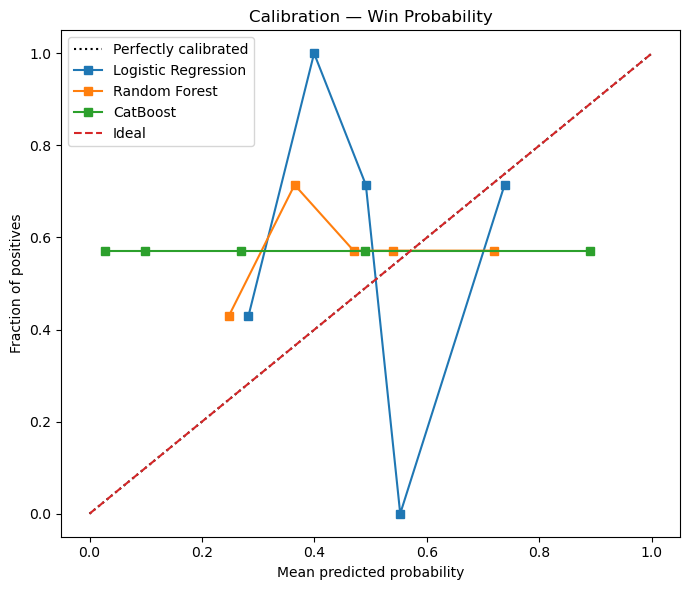

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))

for name, p_test in predictions.items():
    CalibrationDisplay.from_predictions(
        y_test,
        p_test,
        n_bins=5,
        strategy="quantile",
        name=name,
        ax=ax,
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Ideal")
ax.set_title("Calibration — Win Probability")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Diễn giải cuối cùng

### Cách đọc kết quả

- **CV leader**: model có `cv_auc_mean` cao nhất.
- **Test ROC-AUC leader**: model có `auc` cao nhất.
- **PR-AUC leader** và **Top-30% Precision leader** được báo cáo độc lập.
- Không coi CV leader mặc nhiên là model tốt nhất trên test.
- Không hard-code số liệu; các giá trị trong phần tổng kết phải lấy từ `results_df`.

### Calibration

Calibration curve chỉ mang tính thăm dò vì test set nhỏ. Không kết luận model đã calibrated tốt chỉ từ vài bin.

### Kết luận DS-04

> Ba baseline đã được xây dựng và đánh giá trên time split không leakage. Kết quả được báo cáo trực tiếp từ `results_df` của run hiện tại. Do test set nhỏ, CV variance đáng kể và calibration có độ bất định cao, kết quả được xem là baseline/sanity check chứ chưa phải bằng chứng về predictive power đủ mạnh cho production.

Không tuning chỉ để đẩy metric lên cao.


## 8. Checklist đạt DS-04 — Win Probability

- Dataset rebuild từ ERPNext API thật
- 1 dòng = 1 Opportunity
- Snapshot `as_of_date` = ngày Quotation đầu tiên
- `out_of_scope_no_quotation` được tách khỏi trainable population
- Time split: `max(train as_of_date) <= min(test as_of_date)`
- Leakage feature `n_quotation_total` đã loại
- Leakage feature `owner_historic_win_rate` đã loại
- Constant feature `opportunity_type` đã loại
- ≥3 baseline
- StratifiedKFold(5)
- ROC-AUC
- PR-AUC
- Top-30%-Precision
- Calibration curve
- CV/sample-size caveat
- Không overclaim predictive performance
- Không tuning chỉ để làm metric đẹp


## 9. Ghi chú về khả năng tái lập

Notebook này đọc:

```text
win_probability_train.csv
win_probability_test.csv
```

Hai file phải là **dataset rebuild mới nhất**, được tạo với DATA_CUTOFF đúng ngày pull thật, tương ứng với:

- Train = 84
- Test = 35
- Feature audit có variation ở `days_lead_to_opp`, `lead_source`, `customer_segment`, `territory`, `discount_rate_at_first_quotation`
- `opportunity_type` constant và bị loại.

Nếu CSV được rebuild lại từ pipeline DS-03, phải chạy lại toàn bộ notebook từ đầu. Không giữ lại metric cũ nếu dataset thay đổi.
